# Master ETL Pipeline
**Mục tiêu:** Tích hợp 3 tập dữ liệu sạch của PC, Console và Mobile thành một bộ dữ liệu đồng nhất phục vụ Dashboard & Phân tích.

### Các bước xử lý chính:
1. Nạp 3 tập dữ liệu đã qua tiền xử lý.
2. Áp dụng chuẩn hóa chỉ số song song (Dual-Metric): Volume & Revenue USD.
3. Đối sánh đa nền tảng (Cross-Platform Fuzzy Matching).
4. Xuất file master `data/processed/master_gaming_dataset.csv`.

In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns



OUTPUT_PATH = os.path.join('..', '..', 'data', 'processed', 'master_gaming_dataset.csv')
PC_PATH = os.path.join('..', '..', 'data', 'processed', 'pc_cleaned.csv')
CONSOLE_PATH = os.path.join('..', '..', 'data', 'processed', 'console_cleaned.csv')
MOBILE_PATH = os.path.join('..', '..', 'data', 'processed', 'mobile_cleaned.csv')
OUTPUT_PATH = os.path.join('..', '..', 'data', 'processed', 'master_gaming_dataset.csv')


df_pc = pd.DataFrame(pd.read_csv(PC_PATH))
df_console = pd.DataFrame(pd.read_csv(CONSOLE_PATH))
df_mobile = pd.DataFrame(pd.read_csv(MOBILE_PATH))

print(df_pc.columns.to_list())
print(df_console.columns.to_list())
print(df_mobile.columns.to_list())

['Game_Title', 'Platform_Category', 'Genre', 'publisher', 'developer', 'release_year', 'Volume_Units', 'IAP_Revenue_USD', 'Paid_Revenue_USD', 'Estimated_Revenue_USD', 'Rating', 'Rating_Tier', 'price_usd', 'discount', 'positive', 'negative', 'ccu']
['Game_Title', 'platform', 'Platform_Category', 'Genre', 'publisher', 'developer', 'release_year', 'Volume_Units', 'IAP_Revenue_USD', 'Paid_Revenue_USD', 'Estimated_Revenue_USD', 'Rating', 'Rating_Tier', 'Console_Maker', 'Console_Gen']
['Game_Title', 'Platform_Category', 'Genre', 'publisher', 'developer', 'release_year', 'Volume_Units', 'IAP_Revenue_USD', 'Paid_Revenue_USD', 'Estimated_Revenue_USD', 'Rating', 'Rating_Tier', 'isFree', 'offers_IAP']


## Gộp các cột từ 3 bảng đã xử lý của 3 nền tảng pc, console và mobile thành 1 bảng master để dễ dàng phân tích ngành Game toàn cầu

In [4]:
cols = ['Game_Title', 'Platform_Category', 'Genre', 'publisher', 'developer', 'release_year', 'Volume_Units', 
        'IAP_Revenue_USD', 'Paid_Revenue_USD', 'Estimated_Revenue_USD', 'Rating_Tier']

master_df = pd.concat(
    [df_pc[cols], df_mobile[cols], df_console[cols]], ignore_index=True
)
master_df

master_df.to_csv(OUTPUT_PATH, index=False)


In [5]:
import pandas as pd
import plotly.express as px

df_region = pd.read_csv('D:/Documents/TuongTacDuLieu/GAMING INDUSTRY ANALYSIS/Gaming-Market-Industry-Analytics/data/processed/revenue_by_region_cleaned.csv', keep_default_na=False)
df_yoy = df_region[df_region['Year'] == 2022].copy()
country_region_map = {
    'USA': 'North America', 'CAN': 'North America', 'GRL': 'North America', 'BMU': 'North America',
    'GBR': 'Europe', 'FRA': 'Europe', 'DEU': 'Europe', 'ITA': 'Europe', 'ESP': 'Europe', 'POL': 'Europe', 'NLD': 'Europe',
    'CHN': 'Asia-Pacific', 'JPN': 'Asia-Pacific', 'KOR': 'Asia-Pacific', 'VNM': 'Asia-Pacific', 'IND': 'Asia-Pacific', 'AUS': 'Asia-Pacific',
    'BRA': 'Latin America', 'MEX': 'Latin America', 'ARG': 'Latin America', 'COL': 'Latin America',
    'SAU': 'Middle East & Africa', 'ARE': 'Middle East & Africa', 'EGY': 'Middle East & Africa', 'ZAF': 'Middle East & Africa'
}
df_map = pd.DataFrame(list(country_region_map.items()), columns=['ISO3', 'Region'])
df_choropleth = pd.merge(df_map, df_yoy, on='Region', how='inner')
fig = px.choropleth(
    df_choropleth,
    locations= "ISO3",
    color= "YoY_Growth_Pct",
    hover_name= "Region",
    hover_data = {
        "ISO3": False,
        "YoY_Growth_Pct": ':.1f%',
        "Share_Pct": ':.1f%'
    },
    color_continuous_scale="RdYlGn",  
    color_continuous_midpoint=0,    
    range_color = [-10, 10],
    title="Tốc Độ Tăng Trưởng Doanh Thu Game Toàn Cầu Theo Khu Vực (2022)",
    labels={'YoY_Growth_Pct': 'Tăng trưởng YoY (%)', 'Share_Pct': 'Thị phần (%)'}
)
fig.update_layout(
    geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular'),
)
fig.show()
df_choropleth[df_choropleth['Year'] ==  2022]

,ISO3,Region,Region_Code,Year,Share_Pct,YoY_Growth_Pct
0,USA,North America,NA,2022,26.2,-5.1
1,CAN,North America,NA,2022,26.2,-5.1
2,GRL,North America,NA,2022,26.2,-5.1
3,BMU,North America,NA,2022,26.2,-5.1
4,GBR,Europe,EU,2022,17.8,-3.5
5,FRA,Europe,EU,2022,17.8,-3.5
6,DEU,Europe,EU,2022,17.8,-3.5
7,ITA,Europe,EU,2022,17.8,-3.5
8,ESP,Europe,EU,2022,17.8,-3.5
9,POL,Europe,EU,2022,17.8,-3.5


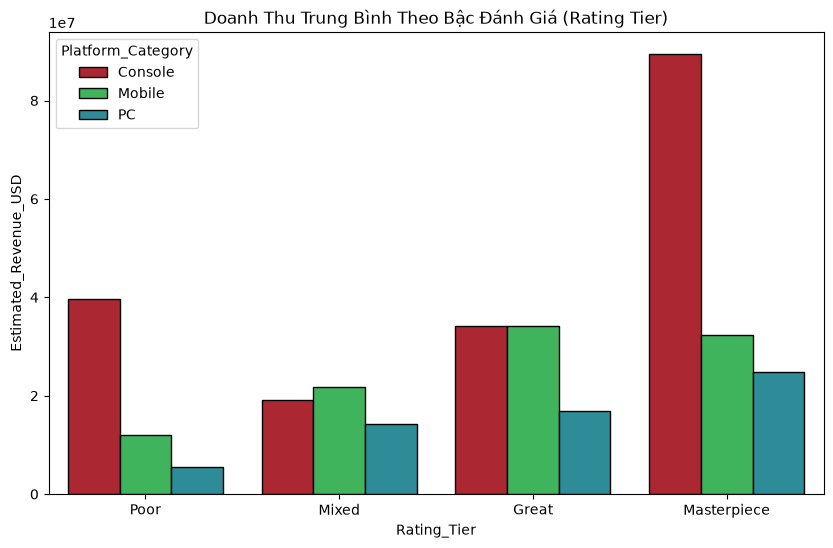

In [6]:
colors = {'PC': '#1b9aaa', 'Console': '#c1121f', 'Mobile': '#2dc653'}
median_revn = master_df.groupby(['Rating_Tier', 'Platform_Category'])['Estimated_Revenue_USD'].mean().reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(
    data=median_revn,
    x='Rating_Tier',
    y='Estimated_Revenue_USD',
    hue='Platform_Category',
    order= ['Poor', 'Mixed', 'Great', 'Masterpiece'],
    palette= colors,
    edgecolor='black'
)
plt.title("Doanh Thu Trung Bình Theo Bậc Đánh Giá (Rating Tier)")
plt.show()

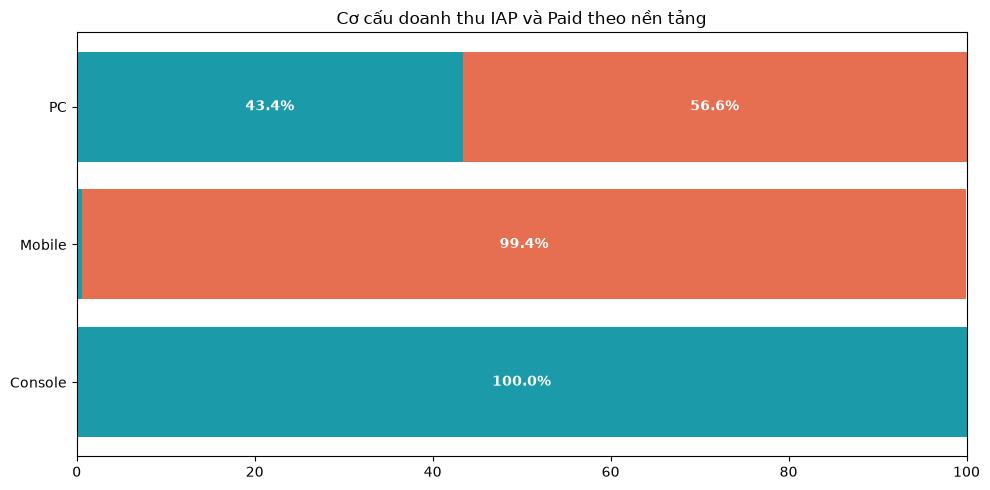

In [7]:
platform_rev = master_df.groupby('Platform_Category')[['Paid_Revenue_USD', 'IAP_Revenue_USD']].sum().reset_index()
total_revenue = platform_rev[['Paid_Revenue_USD', 'IAP_Revenue_USD']].sum(axis=1)
platform_rev_pct = platform_rev.copy()
platform_rev_pct[['Paid_Revenue_USD', 'IAP_Revenue_USD']] = (platform_rev[['Paid_Revenue_USD', 'IAP_Revenue_USD']].div(total_revenue.replace(0, np.nan), axis=0) * 100)
fig, ax = plt.subplots(figsize= (10, 5))
y_pos = np.arange(len(platform_rev_pct))
ax.barh(
    y_pos,
    platform_rev_pct["Paid_Revenue_USD"],
    color="#1b9aaa",
    label="Paid Revenue"
)
ax.barh(
    y_pos,
    platform_rev_pct["IAP_Revenue_USD"],
    left=platform_rev_pct["Paid_Revenue_USD"],
    color="#e76f51",
    label="IAP Revenue"
)
for i, (paid_value, iap_value) in enumerate(zip(platform_rev_pct["Paid_Revenue_USD"], platform_rev_pct["IAP_Revenue_USD"])):
    if paid_value >= 5:
        ax.text(
            paid_value / 2,
            i,
            f"{paid_value:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=10,
            fontweight="bold"
        )
    if iap_value >= 5:
        ax.text(
            paid_value + iap_value / 2,
            i,
            f"{iap_value:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=10,
            fontweight="bold"
        )
plt.title("Cơ cấu doanh thu IAP và Paid theo nền tảng")
ax.set_yticks(y_pos)
ax.set_yticklabels(platform_rev_pct["Platform_Category"].astype(str))
plt.tight_layout()
plt.show()